In [1]:
import torch
import librosa
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from muq import MuQ
import re 


/home/aguerouani/free-gen-playlist/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
from embedding_extraction import extract_embedding
data_dir = '../Data/4qDataset/MERAudio'

embeddings = []
filenames = []
labels = []

mp3_entries = []


assert os.path.isdir(data_dir), f"Dossier introuvable : {data_dir}"
# 🔹 Parcours du dataset
for root, _, files in os.walk(data_dir):
    label = os.path.basename(root)   # Q1, Q2, Q3, Q4
    
    # On ignore le dossier racine lui-même
    if label == os.path.basename(data_dir):
        continue
    
    for f in files:
        if f.lower().endswith(".mp3"):
            full_path = os.path.join(root, f)
            mp3_entries.append((full_path, f, label))


# 🔹 Extraction des embeddings
for full_path, fname, label in mp3_entries:
    emb = extract_embedding(full_path)
    
    if emb is None:
        print(f"⚠️ Embedding échoué : {fname}")
        continue
    
    embeddings.append(emb)
    filenames.append(fname)
    labels.append(label)
    
    print(f"✅ {fname} | Label : {label} | Shape : {emb.shape}")

# 🔹 Conversion
embeddings = np.array(embeddings)

# 🔹 Sauvegarde CSV
df = pd.DataFrame(embeddings)
df["label"] = labels
df["filename"] = filenames
df.to_csv("meraudio_embeddings.csv", index=False)

# 🔹 Sauvegarde PyTorch
torch.save(
    {
        "embeddings": torch.tensor(embeddings),
        "labels": labels,
        "filenames": filenames
    },
    "meraudio_embeddings.pt"
)

print("✅ Extraction terminée")
print("Shape finale :", embeddings.shape)

✅ MT0009293226.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0033097471.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0006810990.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0030160582.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0003262589.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0011697297.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0006903607.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0004715422.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0005550288.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0012168286.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0006292011.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0036111736.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0010490157.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0000729701.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0001333258.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0013885218.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0028172888.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0008511909.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0001891229.mp3 | Label : Q2 | Shape : (1024,)
✅ MT0008137868.mp3 | Label : Q2 | Shape : (1024,)


Loaded embeddings shape: (900, 1024)
t-SNE result shape: (900, 2)


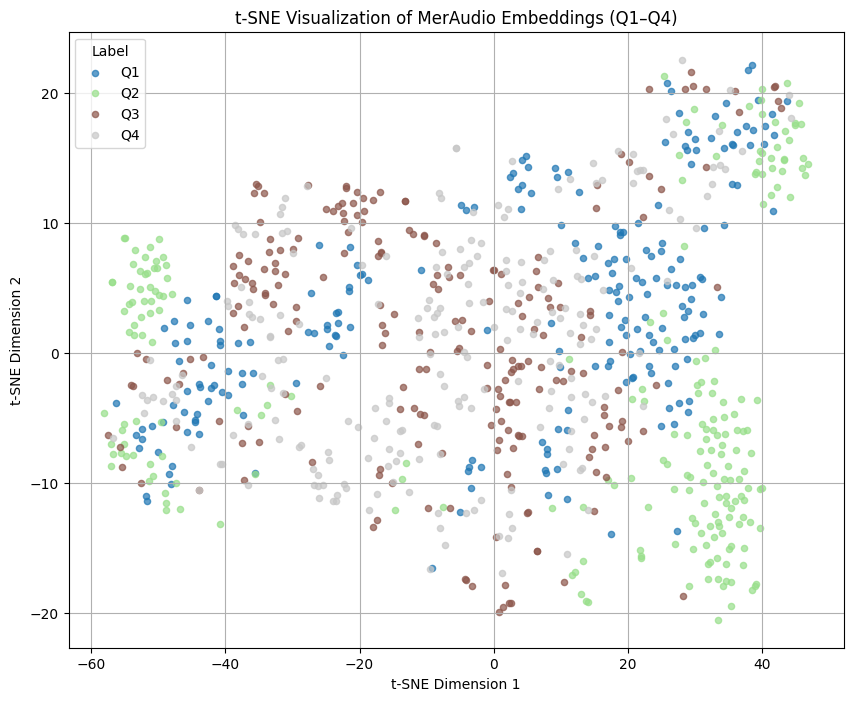

✅ t-SNE plot saved as tsne_meraudio_embeddings_4q.png


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# 🔹 Chargement
csv_path = "meraudio_embeddings.csv"
data = pd.read_csv(csv_path)

labels = data["label"].to_numpy()
filenames = data["filename"].to_numpy()

data = data.drop(columns=["label", "filename"])
embeddings = data.to_numpy()

print("Loaded embeddings shape:", embeddings.shape)

# 🔹 t-SNE
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=min(30, len(embeddings) - 1),  # sécurité
    init="pca",
    learning_rate="auto"
)

X_2d = tsne.fit_transform(embeddings)
print("t-SNE result shape:", X_2d.shape)

# 🔹 Plot
plt.figure(figsize=(10, 8))

unique_labels = np.unique(labels)
n_classes = len(unique_labels)

cmap = plt.get_cmap("tab20")
colors = [cmap(i / n_classes) for i in range(n_classes)]

for cls, color in zip(unique_labels, colors):
    mask = labels == cls
    plt.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        label=cls,
        color=color,
        alpha=0.7,
        s=20
    )

plt.title("t-SNE Visualization of MerAudio Embeddings (Q1–Q4)")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Label")
plt.grid(True)

plt.savefig("tsne_meraudio_embeddings_4q.png", dpi=300)
plt.show()

print("✅ t-SNE plot saved as tsne_meraudio_embeddings_4q.png")
